© 2026 by Tamás Takács is licensed under CC BY-NC-SA 4.0. To view a copy of this license, visit https://creativecommons.org/licenses/by-nc-sa/4.0/

# **Tiers and Optimizers (SOLUTION)**

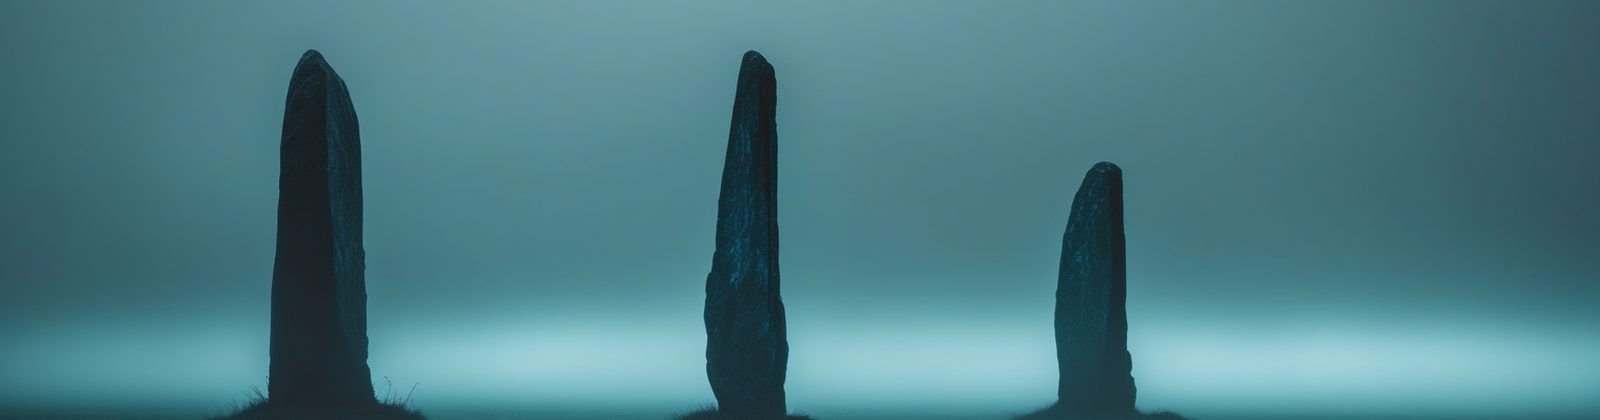

## **Task overview**

Four parts on one set of features: a logistic regression trained twice by gradient descent, a four-class network, per-class metrics computed from a supplied log of predictions, and one logistic regression trained with four optimizers.

| Part | Task | Points |
|---|---|---:|
| a | Two loss traces from the same descent, scaled and unscaled | 25 |
| b | Four-class tier predictions | 25 |
| c | Precision, recall and F1 per class, from a supplied log | 25 |
| d | One logistic regression, four optimizers | 25 |

Parts a, c and d are deterministic arithmetic with exactly one right answer, and no hidden layer is involved in any of them. Part b is graded on how many predictions are correct.



## **Task specification**

**Part a, 20 rows.** Run **logistic regression by gradient descent, in NumPy**, twice on the same two columns of `train.csv`: `income` and `tenure_months`, in that order. Impute missing values with that column's median over `train.csv` first.

The recipe is identical both times, so the only difference is the features:

- weights start at zero, bias starts at zero
- full batch, learning rate `0.05`, `400` steps
- at each step: `z = X @ w + b`, `p = 1 / (1 + exp(-clip(z, -500, 500)))`, then the mean binary cross-entropy against `churn` with `1e-12` added inside each logarithm, `-mean(y * log(p + 1e-12) + (1 - y) * log(1 - p + 1e-12))`, then `w -= 0.05 * X.T @ (p - y) / n` and `b -= 0.05 * mean(p - y)`
- record the loss **before** each update

Run 1 uses the columns **as they are**. Run 2 uses them **standardised**, each column minus its own mean and divided by its own standard deviation (population).

Report the loss **times 1000, rounded**, at steps `0, 5, 10, 20, 40, 80, 140, 220, 310, 399`: rows `0..9` are the unscaled run, rows `10..19` the standardised one.

`income` is in the tens of thousands and `tenure_months` stays below 180. One of the two runs does not converge; a plot of both traces shows which.

**Part b, one row per row of `tier_test.csv`, in file order.** Predict the `tier`, reported as an integer: `0` bronze, `1` silver, `2` gold, `3` platinum. The test set holds **equal numbers of all four tiers**, so guessing one class throughout scores 25%.

Preprocess the features: impute missing values with the training median, standardise with training statistics, then one-hot encode the three categorical columns. The last layer is `Linear(..., 4)` with no activation after it, and the loss is `CrossEntropyLoss`, which takes **raw logits** and computes the softmax internally, with the integer tier as the target.

**Part c, 12 rows.** `audit_log.csv` has two columns, `truth` and `predicted`, both tier names. For each tier in the order bronze, silver, gold, platinum, report **precision, recall and F1**, each times 1000 and rounded. Rows `0..2` are bronze, rows `3..5` silver, and so on.

For one class the model made no predictions at all, so precision divides by zero. Report `0` for any metric whose denominator is zero rather than crashing or skipping the row. That class makes up under 6% of the log's rows, so the overall accuracy changes little when every one of them is wrong.

**Part d, 16 rows.** Logistic regression in PyTorch on the two columns of part a, `income` and `tenure_months`, imputed with the training medians and **standardised** as in run 2 of part a. The target is `churn` as a float tensor of shape `(n, 1)`. The model is `nn.Linear(2, 1)` with its weight and bias set to `0`, the loss `nn.BCEWithLogitsLoss()`, and each of `100` full-batch steps computes the loss, then calls `zero_grad()`, `backward()` and `step()`. Four runs, each starting from zero, with these optimizers:

1. `torch.optim.SGD(model.parameters(), lr=0.05)`
2. the same with `momentum=0.9`
3. `torch.optim.Adam(model.parameters(), lr=0.05)`
4. `torch.optim.SGD(model.parameters(), lr=0.05, weight_decay=0.2)`

- rows `0..11`: for each run in this order, the loss **before** the update at steps `10` and `40`, then the loss after the last step, all **times 1000**. Rows `0..2` are run 1.
- rows `12..15`: the two weights after the last step of run 1, then of run 4, **times 1000**.

## **Useful Links**

- [`nn.CrossEntropyLoss`](https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html)
- [`nn.MSELoss`](https://pytorch.org/docs/stable/generated/torch.nn.MSELoss.html)
- [`Dataset` and `DataLoader`](https://pytorch.org/tutorials/beginner/basics/data_tutorial.html)
- [Precision and recall](https://en.wikipedia.org/wiki/Precision_and_recall)
- [`torch.optim`](https://docs.pytorch.org/docs/stable/optim.html), for `SGD`, `momentum`, `weight_decay` and `Adam`

## **Setup and data**

In [ ]:
# ══════════════════════════════════════════════════════════
# Setup. DO NOT MODIFY.
# ══════════════════════════════════════════════════════════
import csv
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

def write_submission(filename, rows):
    """Write [(id, target), ...] as a DOCK-ready CSV."""
    with open(filename, "w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow(["id", "target"])
        for row_id, target in rows:
            writer.writerow([int(row_id), int(target)])
    print(f"wrote {filename}: {len(rows)} rows")

def _find(name):
    here = Path(name)
    return here if here.exists() else Path("data") / name

def load(name):
    with open(_find(name), newline="", encoding="utf-8") as f:
        return list(csv.DictReader(f))

NUMERIC = ["age", "income", "tenure_months", "score"]
CATEGORICAL = ["region", "plan", "channel"]
CATEGORIES = {
    "region": ["North", "Harbour", "Midland", "Eastfield", "Southgate", "Upland"],
    "plan": ["basic", "standard", "premium", "legacy"],
    "channel": ["shop", "phone", "online"],
}
TIERS = ["bronze", "silver", "gold", "platinum"]

train = load("train.csv")
tier_test = load("tier_test.csv")
audit = load("audit_log.csv")

print(f"train {len(train)}, tier_test {len(tier_test)}, audit_log {len(audit)}")
print("train columns:", list(train[0]))
print("audit log first rows:", audit[:3])

---
## **Part a: The same descent, twice (25 points)**

NumPy only, no PyTorch: every term of the update is written out.

Submission: `part1_submission.csv`, 20 rows, uploaded to part a.

In [ ]:
def column(records, name):
    return np.array([float(r[name]) if r[name] != "" else np.nan for r in records])

med = {c: float(np.nanmedian(column(train, c))) for c in NUMERIC}
X = np.stack([np.where(np.isnan(column(train, c)), med[c], column(train, c))
              for c in ["income", "tenure_months"]], axis=1)
y = np.array([float(r["churn"]) for r in train])

CHECKPOINTS = [0, 5, 10, 20, 40, 80, 140, 220, 310, 399]

def trace(x, y, standardise):
    x = x.astype(float).copy()
    if standardise:
        x = (x - x.mean(axis=0)) / x.std(axis=0)
    w, b, out = np.zeros(x.shape[1]), 0.0, []
    for step in range(400):
        z = x @ w + b
        p = 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))
        loss = -np.mean(y * np.log(p + 1e-12) + (1 - y) * np.log(1 - p + 1e-12))
        if step in CHECKPOINTS:
            out.append(loss)
        err = p - y
        w -= 0.05 * (x.T @ err) / len(y)
        b -= 0.05 * err.mean()
    return out

raw, scaled = trace(X, y, False), trace(X, y, True)
part1 = [(i, int(round(v * 1000))) for i, v in enumerate(raw)]
part1 += [(10 + i, int(round(v * 1000))) for i, v in enumerate(scaled)]

plt.figure(figsize=(7, 3))
plt.plot(CHECKPOINTS, raw, "o-", label="unscaled")
plt.plot(CHECKPOINTS, scaled, "o-", label="standardised")
plt.yscale("log"); plt.xlabel("step"); plt.ylabel("loss"); plt.legend()
plt.tight_layout(); plt.show()

write_submission("part1_submission.csv", part1)
part1[:6]

---
## **Part b: Four classes (25 points)**

Submission: `part2_submission.csv`, one row per test row, uploaded to part b.

In [ ]:
def numeric_block(records):
    return np.stack([np.where(np.isnan(column(records, c)), med[c], column(records, c))
                     for c in NUMERIC], axis=1)

num_train = numeric_block(train)
mean, std = num_train.mean(axis=0), num_train.std(axis=0)

def features(records):
    blocks = [(numeric_block(records) - mean) / std]
    for cat in CATEGORICAL:
        v = np.array([r[cat] for r in records])
        blocks.append(np.stack([(v == lv).astype(float) for lv in CATEGORIES[cat]], axis=1))
    return np.concatenate(blocks, axis=1)

xtr, xte = features(train), features(tier_test)
ytr = np.array([TIERS.index(r["tier"]) for r in train])

class TierNet(nn.Module):
    def __init__(self, n_in):
        super().__init__()
        self.stack = nn.Sequential(
            nn.Linear(n_in, 48), nn.ReLU(),
            nn.Linear(48, 24), nn.ReLU(),
            nn.Linear(24, 4))            # four raw logits, no softmax here

    def forward(self, x):
        return self.stack(x)

torch.manual_seed(42)
net = TierNet(xtr.shape[1])
opt = torch.optim.Adam(net.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()          # takes logits and integer labels
x = torch.tensor(xtr, dtype=torch.float32)
yy = torch.tensor(ytr, dtype=torch.long)
g = torch.Generator().manual_seed(42)
for epoch in range(40):
    perm = torch.randperm(len(x), generator=g)
    for i in range(0, len(x), 128):
        b = perm[i:i + 128]
        opt.zero_grad()
        loss_fn(net(x[b]), yy[b]).backward()
        opt.step()

with torch.no_grad():
    pred = net(torch.tensor(xte, dtype=torch.float32)).argmax(dim=1).numpy()
part2 = [(i, int(v)) for i, v in enumerate(pred)]

write_submission("part2_submission.csv", part2)
part2[:8]

---
## **Part c: Reading an imbalanced result (25 points)**

Compute the overall accuracy of the log, then the per-class numbers, and compare them.

Submission: `part3_submission.csv`, 12 rows, uploaded to part c.

In [ ]:
truth = np.array([TIERS.index(r["truth"]) for r in audit])
pred_log = np.array([TIERS.index(r["predicted"]) for r in audit])
print(f"overall accuracy of the log: {(truth == pred_log).mean():.3f}")

part3, k = [], 0
for c in range(4):
    tp = int(((pred_log == c) & (truth == c)).sum())
    fp = int(((pred_log == c) & (truth != c)).sum())
    fn = int(((pred_log != c) & (truth == c)).sum())
    prec = tp / (tp + fp) if tp + fp else 0.0      # zero denominator -> 0
    rec = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    print(f"  {TIERS[c]:<9} precision {prec:.3f}  recall {rec:.3f}  F1 {f1:.3f}")
    for v in (prec, rec, f1):
        part3.append((k, int(round(v * 1000)))); k += 1

write_submission("part3_submission.csv", part3)
part3

---
## **Part d: Four optimizers (25 points)**

The four runs differ only in the optimizer, and each starts from zero weights. `momentum` and `weight_decay` are arguments of `torch.optim.SGD`; plotting the four loss curves shows how the runs differ.

Submission: `part4_submission.csv`, 16 rows, uploaded to part d.

In [ ]:
Xs = torch.tensor((X - X.mean(axis=0)) / X.std(axis=0), dtype=torch.float32)   # X and y from part a
Ys = torch.tensor(y, dtype=torch.float32).reshape(-1, 1)

def run(make_optimizer):
    model = nn.Linear(2, 1)
    with torch.no_grad():
        model.weight.zero_()
        model.bias.zero_()
    opt = make_optimizer(model.parameters())
    loss_fn = nn.BCEWithLogitsLoss()
    seen, curve = [], []
    for step in range(100):
        loss = loss_fn(model(Xs), Ys)
        curve.append(loss.item())
        if step in (10, 40):
            seen.append(loss.item())
        opt.zero_grad()
        loss.backward()
        opt.step()
    with torch.no_grad():
        seen.append(loss_fn(model(Xs), Ys).item())
    plt.plot(curve)
    return seen, model.weight.reshape(-1).tolist()

plt.figure(figsize=(7, 3))
runs = [run(lambda p: torch.optim.SGD(p, lr=0.05)),
        run(lambda p: torch.optim.SGD(p, lr=0.05, momentum=0.9)),
        run(lambda p: torch.optim.Adam(p, lr=0.05)),
        run(lambda p: torch.optim.SGD(p, lr=0.05, weight_decay=0.2))]
plt.legend(["SGD", "momentum", "Adam", "weight decay"]); plt.xlabel("step"); plt.ylabel("loss")
plt.tight_layout(); plt.show()

values = [v for losses, _ in runs for v in losses] + runs[0][1] + runs[3][1]
part4 = list(enumerate(int(round(v * 1000)) for v in values))

write_submission("part4_submission.csv", part4)
part4

In [ ]:
# ── Evaluator reproduction: mirrors grader/_common.py exactly ──
def exact_match_points(rows, solution_csv, max_score):
    with open(solution_csv, newline="", encoding="utf-8") as f:
        gt = {int(r["id"]): int(r["target"]) for r in csv.DictReader(f)}
    submitted = {int(i): int(t) for i, t in rows}
    assert set(submitted) == set(gt), "id set mismatch"
    correct = sum(1 for k in gt if submitted[k] == gt[k])
    return int(round(correct / len(gt) * max_score))


total = 0
for n, rows, mx in ((1, part1, 25), (2, part2, 25), (3, part3, 25), (4, part4, 25)):
    pts = exact_match_points(rows, f"grader/{n}_solution.csv", mx)
    total += pts
    print(f"part {n}: {pts}/{mx}")
print(f"total:  {total}/100")

---
## **Submission**

Upload each CSV to its own part on DOCK.

